In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from pathlib import Path

In [2]:
path2figs = Path("figs")
path2figs.mkdir(parents=True, exist_ok=True)
path2data = Path("../data")
path2screen = path2data / "image_screen.csv"

## Image screen: change in green cells between 3 h and 12 h

Each well (`image_screen_folder`, `index`) is imaged at 3 h and 12 h. We pair the two
timepoints per well and look at the change in green cells. Folder letters `a`–`i` are the
screened factors and the trailing `H`/`L` is the dose (`H` = 50 ng/mL, `L` = 10 ng/mL);
`va`/`vb`/`vc` are vehicle controls.

In [3]:
# pair the 3 h and 12 h images of each well
df = pd.read_csv(path2screen)
df_screen = df.pivot_table(index=['image_screen_folder', 'index'], columns='time',
                           values=['num_green_cells', 'total_num_cells'])
df_screen.columns = ['_'.join(c) for c in df_screen.columns]
df_screen = df_screen.reset_index()

drug_map = {'a': 'EGF', 'b': 'NRG1', 'c': 'PDGF', 'd': 'FGF', 'e': 'IGF-1',
            'f': 'HB-EGF', 'g': 'MDK', 'h': 'WNT-11', 'i': 'ANGPTL4'}

def _parse_folder(folder):
    if folder.startswith('v'):
        return 'Vehicle', 'Vehicle'
    return drug_map[folder[0]], ('50 ng/mL' if folder[1] == 'H' else '10 ng/mL')

df_screen[['drug', 'dose']] = df_screen['image_screen_folder'].apply(
    lambda f: pd.Series(_parse_folder(f)))

# g(12 h) - g(3 h)
df_screen['g_diff'] = df_screen['num_green_cells_12hr'] - df_screen['num_green_cells_3hr']

# [g / (g + r)](12 h) - [g / (g + r)](3 h), taking g + r = total number of cells
df_screen['frac_12hr'] = df_screen['num_green_cells_12hr'] / df_screen['total_num_cells_12hr']
df_screen['frac_3hr'] = df_screen['num_green_cells_3hr'] / df_screen['total_num_cells_3hr']
df_screen['frac_diff'] = df_screen['frac_12hr'] - df_screen['frac_3hr']

In [4]:
# left-to-right order; treated wells are black (dose is shown by the row label),
# vehicle is grey so the control stands out
drug_order = ['Vehicle', 'ANGPTL4', 'WNT-11', 'MDK', 'HB-EGF', 'IGF-1', 'FGF', 'PDGF', 'NRG1', 'EGF']
dose_color = {'50 ng/mL': 'black', '10 ng/mL': 'black', 'Vehicle': '#999999'}
median_color = '#e41a1c'


def screen_figure(savename='screen_green_change.pdf'):
    sns.set_theme(style='whitegrid', font_scale=1.4)
    # columns: absolute count change (left) and relative g/(g+r) change (right)
    metrics = [
        ('g_diff', r'$g(12\,h) - g(3\,h)$', False),
        ('frac_diff', r'$g/(g+r)$:  $(12\,h) - (3\,h)$', True),
    ]
    doses = ['50 ng/mL', '10 ng/mL']

    # rows: dose, columns: metric; y-axis shared within each column (metric)
    fig, axes = plt.subplots(len(doses), len(metrics), figsize=(22, 11),
                             sharex=True, sharey='col')
    rng = np.random.default_rng(0)

    for r, dose in enumerate(doses):
        for c, (value_col, title, as_percent) in enumerate(metrics):
            ax = axes[r][c]
            for i, drug in enumerate(drug_order):
                group_dose = 'Vehicle' if drug == 'Vehicle' else dose
                vals = df_screen.loc[(df_screen.drug == drug) & (df_screen.dose == group_dose), value_col].values
                if len(vals) == 0:
                    continue
                xs = i + rng.uniform(-0.12, 0.12, size=len(vals))  # horizontal jitter
                ax.scatter(xs, vals, s=55, color=dose_color[group_dose], alpha=0.85,
                           edgecolor='white', linewidth=0.6, zorder=3)
                # red line at the group median
                ax.hlines(np.median(vals), i - 0.22, i + 0.22, color=median_color, lw=3.5, zorder=4)

            ax.axhline(0, color='0.5', lw=1.2, ls='--', zorder=1)
            if as_percent:
                ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
            if r == 0:
                ax.set_title(title, fontweight='bold', pad=10)   # column = metric
            if c == 0:
                ax.set_ylabel(dose, fontweight='bold')           # row = dose

    axes[0][0].set_xlim(-0.6, len(drug_order) - 0.4)
    for c in range(len(metrics)):
        axes[-1][c].set_xticks(range(len(drug_order)))
        axes[-1][c].set_xticklabels(drug_order, rotation=40, ha='right')

    handles = [
        Line2D([], [], marker='o', ls='', color='black', label='treated'),
        Line2D([], [], marker='o', ls='', color=dose_color['Vehicle'], label='vehicle'),
        Line2D([], [], color=median_color, lw=3.5, label='median'),
    ]

    fig.tight_layout()
    # legend in a horizontal row, centered below the figure
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=3, frameon=False)
    fig.savefig(path2figs / savename, bbox_inches='tight')
    return fig

### Change in green cells: absolute count (left) and relative $g/(g+r)$ (right)

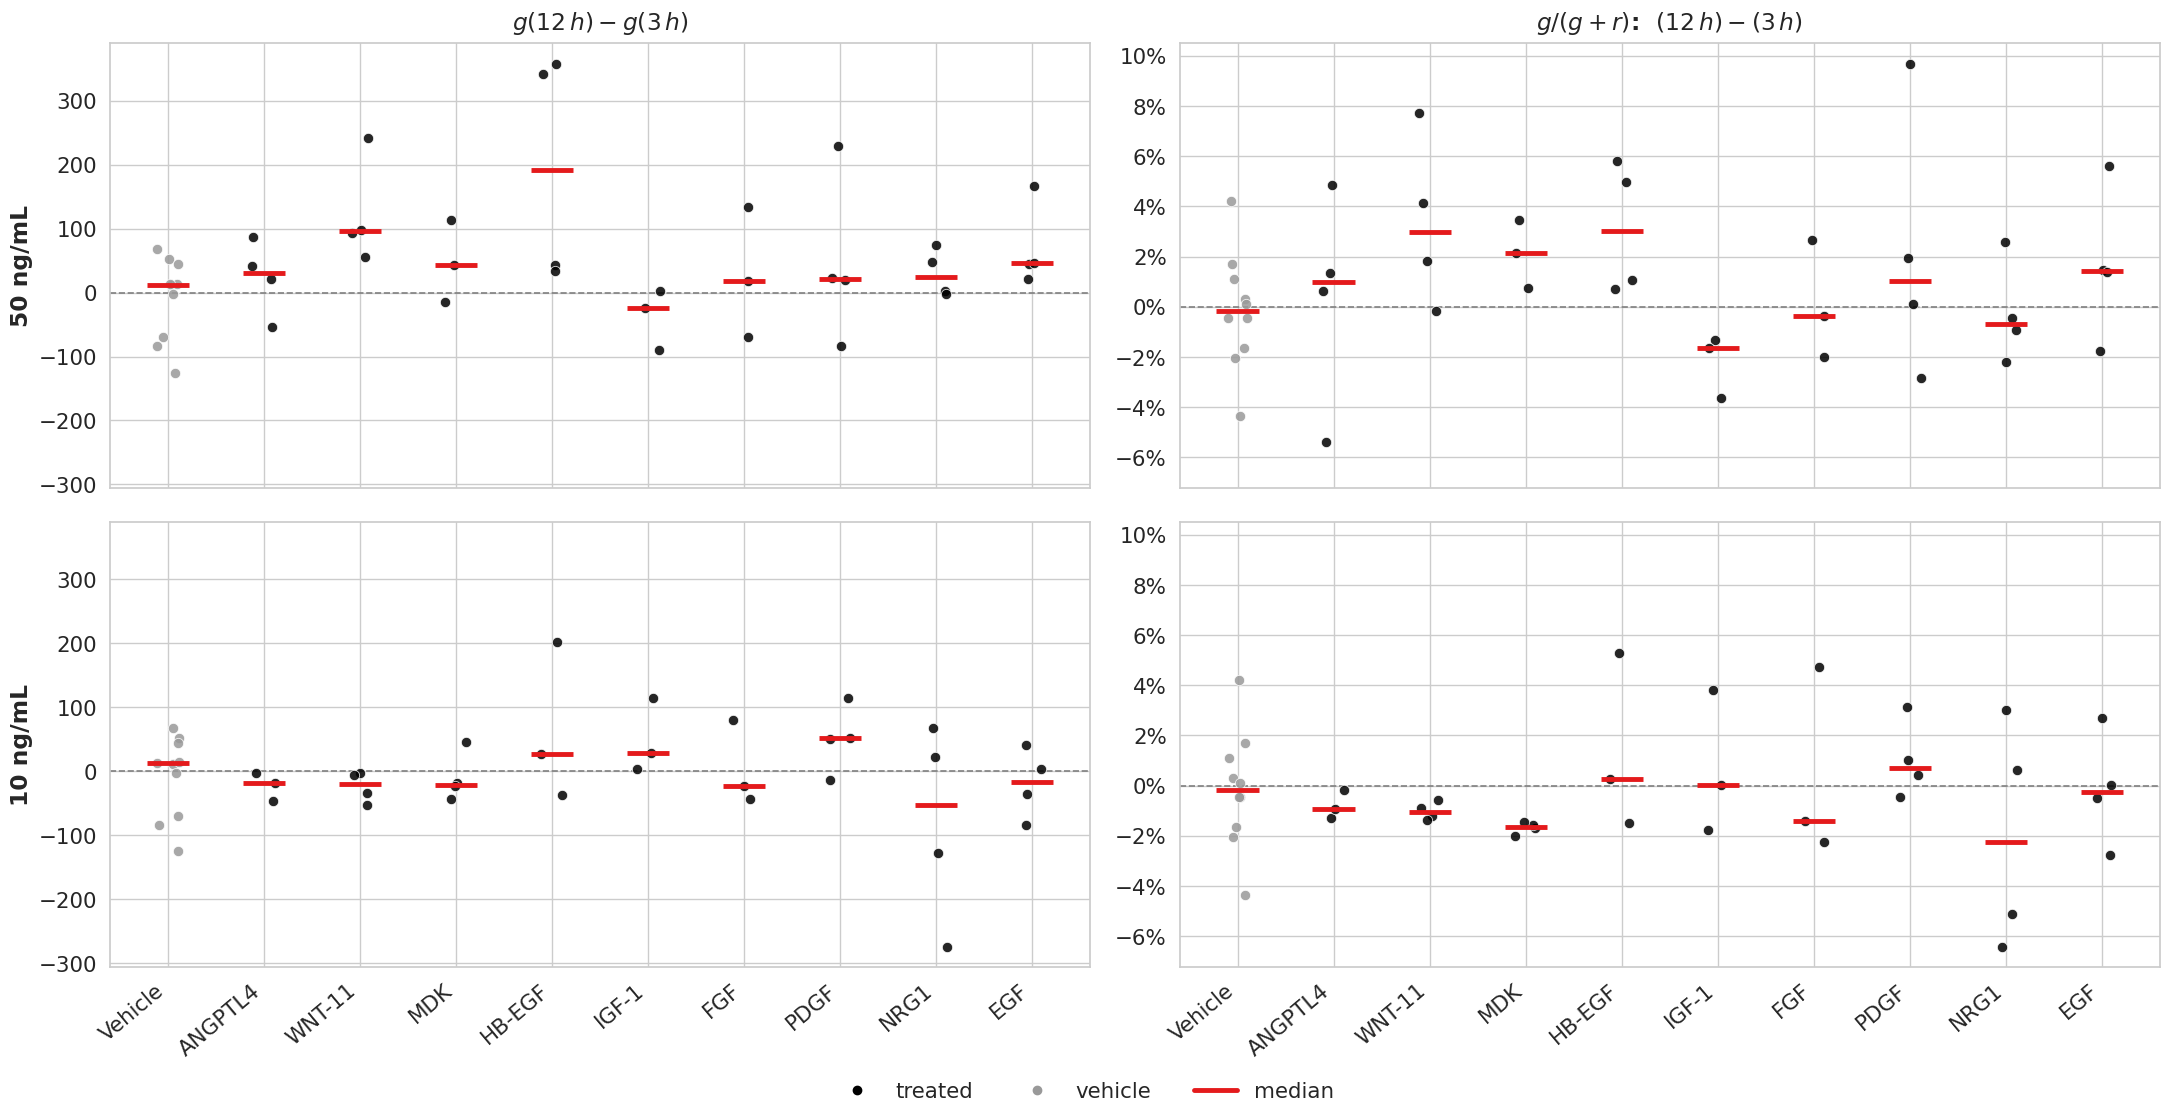

In [5]:
screen_figure('screen_green_change.pdf')
plt.show()